# **Notebook 3 - Python Workflows**

In this notebook, **you'll learn how SHOTpy fits into a broader Python ecosystem** (*e.g.*, by using NumPy, pandas, matplotlib, SciPy, machine learning pipelines, data pipelines).

## Table of Contents
0. [Setup](#0-setup)
1. [Bin Packing Problem](#1-bin-packing-problem)

    1.1. Load Problem Data

    1.2. Build and Solve Model

    1.3. Visualize and Analyze Results

    1.4. Callback-Based Extension

2. [Notebook 3 - Key Takeaways](#2-key-takeaways)

## **0. Setup**

First, install SHOTpy and the Python libraries used in this notebook, then import them.

In [1]:
%pip install SHOTpy pandas matplotlib

Note: you may need to restart the kernel to use updated packages.


In [2]:
import SHOTpy

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import HTML, display
from mpl_toolkits.mplot3d.art3d import Poly3DCollection

## **1. Bin Packing Problem**

The **Bin Packing Problem (BPP)** is a classic combinatorial optimization problem: given a set of items each (boxes, packages, items) with a certain size (width × height × depth), pack them all into the fewest possible bins without exceeding each bin's capacity.

In this formulation we replace the original continuous-angle rotation (which introduced a nonlinear unit-circle constraint) with **axis-aligned 90° rotations only**. Each item may be placed in any of the **6 distinct dimension permutations** of (W, D, H), selected by binary variables.


**Sets**
- $I$: Set of items, indexed by $i$
- $J$: Set of potential bins, indexed by $j$
- $P = \{0,\dots,5\}$: Set of orientation indices (the 6 axis-aligned permutations of W, D, H)

**Parameters**
- $w_i, d_i, h_i$: Width, depth, height of item $i \in I$ in its canonical orientation
- $W, D, H$: Bin dimensions
- $M$: Big-M 
- $\lambda$: Large positive penalty coefficient used to bias the optimization toward solutions with fewer bins
- $(\alpha_p, \beta_p, \gamma_p)$: Effective (width, depth, height) multipliers for permutation $p \in P$, drawn from the 6 permutations of $(w_i, d_i, h_i)$:
$$
\begin{array}{c|ccc}
p & \alpha & \beta & \gamma \\ \hline
0 & w & d & h \\
1 & w & h & d \\
2 & d & w & h \\
3 & d & h & w \\
4 & h & w & d \\
5 & h & d & w
\end{array}
$$



**Variables**

*Bin assignments*
- $x_{ij} \in \{0,1\}$: 1 if item $i$ is assigned to bin $j$
- $y_j \in \{0,1\}$: 1 if bin $j$ is used

*Item placement*
- $X_i, Y_i, Z_i \ge 0$: Coordinates of the lower-left-front corner of item $i$

*Orientation (axis-aligned, binary)*
- $r_{ip} \in \{0,1\}$: 1 if item $i$ uses permutation $p$  
  Exactly one permutation is active: $\sum_{p} r_{ip} = 1$

*Effective dimensions (auxiliary continuous, linearise the product $r_{ip} \cdot \text{dim}$)*
- $\tilde{w}_i, \tilde{d}_i, \tilde{h}_i \ge 0$: Effective width, depth, height of item $i$ after orientation selection

$$
\tilde{w}_i = \sum_{p} \alpha_p^i\, r_{ip}, \quad
\tilde{d}_i = \sum_{p} \beta_p^i\, r_{ip}, \quad
\tilde{h}_i = \sum_{p} \gamma_p^i\, r_{ip}
$$


*Relative positioning*

For every pair of items $i < k$:
- $L_{ik}, R_{ik}, F_{ik}, B_{ik}, U_{ik}, D_{ik} \in \{0,1\}$: Six separation indicators (left/right/front/behind/below/above)

**Model**
$$
\begin{align}
\min \quad &
 \lambda\sum_{j \in J} y_j + \sum_{i \in I} (X_i^2 + Y_i^2 + Z_i^2)
&& \text{(minimize number of bins while preferring compact item placement to one corner)}
\\[6pt]
\text{s.t.} \quad
&
\sum_{j \in J} x_{ij} = 1,
\quad \forall i \in I
&& \text{(each item assigned to exactly one bin)}
\\[6pt]
&
x_{ij} \le y_j,
\quad \forall i \in I,\; j \in J
&& \text{(bin must be open if used)}
\\[6pt]
& \sum_{p \in P} r_{ip} = 1, \quad \forall i \in I
&& \text{(exactly one orientation per item)}
\\[6pt]
&
X_i + \tilde{w}_i \le W + M(1-x_{ij}),
\quad \forall i \in I,\; j \in J
&& \text{(item fits within bin width)}
\\
&
Y_i + \tilde{d}_i \le D + M(1-x_{ij}),
\quad \forall i \in I,\; j \in J
&& \text{(item fits within bin depth)}
\\
&
Z_i + \tilde{h}_i \le H + M(1-x_{ij}),
\quad \forall i \in I,\; j \in J
&& \text{(item fits within bin height)}
\\[6pt]
&
X_i + \tilde{w}_i \le X_k + M(1-L_{ik}), \quad \forall i < k
&& \text{(item $i$ left of item $k$)}
\\
&
X_k + \tilde{w}_k \le X_i + M(1-R_{ik}), \quad \forall i < k
&& \text{(item $i$ right of item $k$)}
\\
&
Y_i + \tilde{d}_i \le Y_k + M(1-F_{ik}), \quad \forall i < k
&& \text{(item $i$ in front of item $k$)}
\\
&
Y_k + \tilde{d}_k \le Y_i + M(1-B_{ik}), \quad \forall i < k
&& \text{(item $i$ behind item $k$)}
\\
&
Z_i + \tilde{h}_i \le Z_k + M(1-U_{ik}), \quad \forall i < k
&& \text{(item $i$ below item $k$)}
\\
&
Z_k + \tilde{h}_k \le Z_i + M(1-D_{ik}), \quad \forall i < k
&& \text{(item $i$ above item $k$)}
\\[6pt]
&
L_{ik}+R_{ik}+F_{ik}+B_{ik}+U_{ik}+D_{ik}
\ge x_{ij}+x_{kj}-1, \quad \forall i < k,\; j \in J
&& \text{(items in same bin must be separated)}
\\[6pt]
&
x_{ij},\, y_j,\, r_{ip} \in \{0,1\}
\\
&
L_{ik},\,R_{ik},\,F_{ik},\,B_{ik},\,U_{ik},\,D_{ik} \in \{0,1\}
\\
&
\tilde{w}_i,\, \tilde{d}_i,\, \tilde{h}_i \ge 0
\end{align}
$$


### **1.1. Load Problem Data**


Item data is stored in `binpacking_items.csv`. We begin by loading it with `pandas`, and computing a few useful statistics.


In [3]:
# Load item data
df = pd.read_csv("binpacking_items.csv")
df["volume"] = df["width"] * df["depth"] * df["height"]

# Display a styled table
display(HTML(df.to_html(index=False)))

# Item set and item data
I = df["item_id"].tolist()
widths = dict(zip(I, df["width"].tolist()))
depths = dict(zip(I, df["depth"].tolist()))
heights = dict(zip(I, df["height"].tolist()))
volumes = dict(zip(I, df["volume"].tolist()))

# Potential bins (worst case: one bin per item)
J = list(range(len(I)))

# Bin dimensions
BIN_WIDTH, BIN_DEPTH, BIN_HEIGHT = 12, 10, 10
BIN_VOLUME = BIN_WIDTH * BIN_DEPTH * BIN_HEIGHT

# Summary statistics
print(f"Number of items   : {len(I)}")
print(f"Total item volume : {sum(volumes.values())}")
print(f"Bin dimensions    : {BIN_WIDTH} × {BIN_DEPTH} × {BIN_HEIGHT}")
print(f"Bin volume        : {BIN_VOLUME}")

item_id,width,depth,height,volume
I001,10,8,5,400
I002,4,6,3,72
I003,12,7,4,336
I004,5,5,5,125
I005,3,6,7,126
I006,6,10,5,300
I007,7,4,10,280
I008,2,2,8,32
I009,2,2,6,24
I010,6,10,4,240


Number of items   : 10
Total item volume : 1935
Bin dimensions    : 12 × 10 × 10
Bin volume        : 1200


Before jumping into optimization, let's use `matplotlib` to get a feel for the item size distribution.

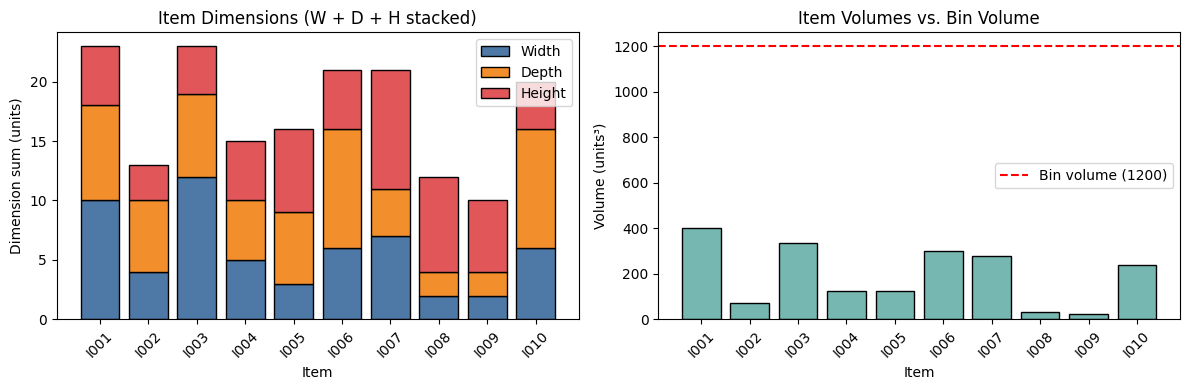

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

x_pos = np.arange(len(I))
w_vals = [widths[i] for i in I]
d_vals = [depths[i] for i in I]
h_vals = [heights[i] for i in I]

# Stacked bar: width / depth / height per item
axes[0].bar(x_pos, w_vals, label='Width', color='#4E79A7', edgecolor='black')
axes[0].bar(x_pos, d_vals, bottom=w_vals, label='Depth', color='#F28E2B', edgecolor='black')
axes[0].bar(x_pos, h_vals, bottom=np.add(w_vals, d_vals), label='Height', color='#E15759', edgecolor='black')
axes[0].set_xticks(x_pos)
axes[0].set_xticklabels(I, rotation=45)
axes[0].set_xlabel('Item')
axes[0].set_ylabel('Dimension sum (units)')
axes[0].set_title('Item Dimensions (W + D + H stacked)')
axes[0].legend()

# Item volumes vs. bin volume
axes[1].bar(x_pos, [volumes[i] for i in I], color='#76B7B2', edgecolor='black')
axes[1].axhline(y=BIN_VOLUME, color='red', linestyle='--', label=f'Bin volume ({BIN_VOLUME})')
axes[1].set_xticks(x_pos)
axes[1].set_xticklabels(I, rotation=45)
axes[1].set_xlabel('Item')
axes[1].set_ylabel('Volume (units³)')
axes[1].set_title('Item Volumes vs. Bin Volume')
axes[1].legend()

plt.tight_layout()
plt.show()

### **1.2. Build and Solve Model**


Now let's build the bin packing model in SHOTpy. The structure follows the same pattern established in Notebook 1: create solver → create problem → add variables, objective and constraints → finalize problem → set problem → solve.

Since we solve the same model again in Section 1.4, the model is built by a function, `build_binpacking_model(solver)`, which returns the finalized problem and its variables. The constraints are written as comparisons that follow the model above, *e.g.*, `X[i] + w_eff[i] <= BIN_WIDTH + M * (1 - x[i, j])`, where `w_eff[i]` is the effective width $\tilde{w}_i$.

In [6]:
# Big-M (>= largest possible effective dimension in any orientation)
M = BIN_WIDTH + BIN_DEPTH + BIN_HEIGHT

# Lambda for objective weighting: prioritise bin count over compact placement
LAMBDA = 1000

# Orientation permutations: the 6 axis-aligned 90° rotations. Each row gives (eff_width, eff_depth, eff_height)
# as indices into (w_i, d_i, h_i), where 0 = w, 1 = d, 2 = h
PERM_DIMS = [
    (0, 1, 2),  # p=0: (w, d, h)  — identity
    (0, 2, 1),  # p=1: (w, h, d)
    (1, 0, 2),  # p=2: (d, w, h)
    (1, 2, 0),  # p=3: (d, h, w)
    (2, 0, 1),  # p=4: (h, w, d)
    (2, 1, 0),  # p=5: (h, d, w)
]
P = list(range(len(PERM_DIMS)))
PERM_LABELS = ["(W,D,H)", "(W,H,D)", "(D,W,H)", "(D,H,W)", "(H,W,D)", "(H,D,W)"]

# Pairs of items i < k
pairs = [(I[a], I[b]) for a in range(len(I)) for b in range(a + 1, len(I))]


def eff_dims(item, p):
    """Return (eff_w, eff_d, eff_h) for the item in orientation p."""
    src = [widths[item], depths[item], heights[item]]
    a, b, g = PERM_DIMS[p]
    return src[a], src[b], src[g]


def build_binpacking_model(solver):
    """Create the bin packing problem; returns the finalized problem and a dict with its variables."""
    problem = SHOTpy.Problem(solver)
    Binary, Real = SHOTpy.VariableType.Binary, SHOTpy.VariableType.Real

    # ── Variables ────────────────────────────────────────────────────────────────
    # x[i, j]          = 1 if item i is placed in bin j
    # y[j]             = 1 if bin j is used
    # X[i], Y[i], Z[i] = coordinates of the lower-left-front corner of item i
    # r[i, p]          = 1 if item i uses orientation p
    # sep[s, i, k]     = 1 if item i is left/right/in front of/behind/below/above (s = L/R/F/B/U/D) item k, i < k
    x = {(i, j): problem.addVariable(f"x_{i}_{j+1}", Binary) for i in I for j in J}
    y = {j: problem.addVariable(f"y_{j+1}", Binary) for j in J}

    X, Y, Z, r = {}, {}, {}, {}
    for i in I:
        X[i] = problem.addVariable(f"X_{i}", Real, 0, BIN_WIDTH)
        Y[i] = problem.addVariable(f"Y_{i}", Real, 0, BIN_DEPTH)
        Z[i] = problem.addVariable(f"Z_{i}", Real, 0, BIN_HEIGHT)
        for p in P:
            r[i, p] = problem.addVariable(f"r_{i}_{p}", Binary)

    sep = {(s, i, k): problem.addVariable(f"{s}_{i}_{k}", Binary) for (i, k) in pairs for s in "LRFBUD"}

    # Effective dimensions of each item, linear in the orientation variables r[i, p]
    w_eff = {i: sum(eff_dims(i, p)[0] * r[i, p] for p in P) for i in I}
    d_eff = {i: sum(eff_dims(i, p)[1] * r[i, p] for p in P) for i in I}
    h_eff = {i: sum(eff_dims(i, p)[2] * r[i, p] for p in P) for i in I}

    # ── Objective: minimize the number of bins, then prefer compact placement in one corner ──
    problem.setObjective(LAMBDA * sum(y[j] for j in J) + sum(X[i]**2 + Y[i]**2 + Z[i]**2 for i in I),
                         SHOTpy.ObjectiveDirection.Minimize)

    # ── Constraints ──────────────────────────────────────────────────────────────
    # Each item assigned to exactly one bin
    for i in I:
        problem.addConstraint(sum(x[i, j] for j in J) == 1, f"assign_{i}")

    # Bin must be open if used
    for i in I:
        for j in J:
            problem.addConstraint(x[i, j] <= y[j], f"open_{i}_{j+1}")

    # Exactly one orientation per item
    for i in I:
        problem.addConstraint(sum(r[i, p] for p in P) == 1, f"orient_{i}")

    # Item fits within the bin
    for i in I:
        for j in J:
            problem.addConstraint(X[i] + w_eff[i] <= BIN_WIDTH + M * (1 - x[i, j]), f"fit_w_{i}_{j+1}")
            problem.addConstraint(Y[i] + d_eff[i] <= BIN_DEPTH + M * (1 - x[i, j]), f"fit_d_{i}_{j+1}")
            problem.addConstraint(Z[i] + h_eff[i] <= BIN_HEIGHT + M * (1 - x[i, j]), f"fit_h_{i}_{j+1}")

    # Non-overlap for every pair of items i < k
    for (i, k) in pairs:
        problem.addConstraint(X[i] + w_eff[i] <= X[k] + M * (1 - sep["L", i, k]), f"left_{i}_{k}")
        problem.addConstraint(X[k] + w_eff[k] <= X[i] + M * (1 - sep["R", i, k]), f"right_{i}_{k}")
        problem.addConstraint(Y[i] + d_eff[i] <= Y[k] + M * (1 - sep["F", i, k]), f"front_{i}_{k}")
        problem.addConstraint(Y[k] + d_eff[k] <= Y[i] + M * (1 - sep["B", i, k]), f"behind_{i}_{k}")
        problem.addConstraint(Z[i] + h_eff[i] <= Z[k] + M * (1 - sep["U", i, k]), f"below_{i}_{k}")
        problem.addConstraint(Z[k] + h_eff[k] <= Z[i] + M * (1 - sep["D", i, k]), f"above_{i}_{k}")

        # Items in the same bin must be separated in at least one direction
        for j in J:
            problem.addConstraint(sum(sep[s, i, k] for s in "LRFBUD") >= x[i, j] + x[k, j] - 1, f"sep_{i}_{k}_{j+1}")

    # Symmetry breaking: bin j can only be used if bin j-1 is used
    for j in range(1, len(J)):
        problem.addConstraint(y[j] <= y[j - 1], f"sym_{j+1}")

    problem.finalize()
    return problem, {"x": x, "y": y, "X": X, "Y": Y, "Z": Z, "r": r}

**A note on solve time:** Proving that a packing is optimal is much harder than finding a good one. With HiGHS, SHOT finds a packing into two bins within a second, but closing the gap to the dual bound takes far longer. We therefore stop the solve after 60 seconds with `Termination.TimeLimit` and use the best packing found so far; the status is then `FeasibleSolution` rather than `OptimalGlobal`. 

In [7]:
# Create solver
solver = SHOTpy.Solver()
solver.updateSetting("Dual.MIP.Solver", int(SHOTpy.MIPSolver.Highs))   # Gurobi, Cplex, Cbc or Highs
solver.updateSetting("Termination.TimeLimit", 60.0)                     # Stop after 60 s with the best packing found

# Create problem
problem, variables = build_binpacking_model(solver)

# Set problem
assert solver.setProblem(problem)

# Solve
assert solver.solveProblem()


 Performing bound tightening on original problem.
  - Bounds for 0 variables tightened in 0.00 s and 1 passes.
  - Objective bounds are: [0, 13440]

 Performing bound tightening on reformulated problem.
  - Bounds for 0 variables tightened in 0.00 s and 1 passes.
  - Objective bounds are: [0, 13440]
Running HiGHS 1.15.1 (git hash: 04024d7): Copyright (c) 2026 under MIT licence terms
Includes third-party software components, see THIRD_PARTY_NOTICES.md for full details
Rows:        1129 lower bounds    less than or equal to       -1e+20 are treated as -Infinity
Rows:        1129 lower bounds    less than or equal to       -1e+20 are treated as -Infinity

╶ Interior point search ──────────────────────────────────────────────────────────────────────────────────────────────╴

 Strategy selected:          cutting plane minimax

Running HiGHS 1.15.1 (git hash: 04024d7): Copyright (c) 2026 under MIT licence terms
Includes third-party software components, see THIRD_PARTY_NOTICES.md for full de

In [8]:
def decode_packing(point, variables):
    """Decode a solution point into bin -> items, item -> (x0, y0, z0) and item -> orientation."""
    x, y, X, Y, Z, r = (variables[name] for name in ("x", "y", "X", "Y", "Z", "r"))
    packing, positions, orientations = {}, {}, {}

    for j in J:
        if round(point[y[j].index]) == 1:
            packing[j] = [i for i in I if round(point[x[i, j].index]) == 1]

            for i in packing[j]:
                positions[i] = (point[X[i].index], point[Y[i].index], point[Z[i].index])
                orientations[i] = next(p for p in P if round(point[r[i, p].index]) == 1)

    return packing, positions, orientations


# Check status
print(f"Status                : {solver.getModelReturnStatus().name} ({solver.getTerminationReason().name})")
print(f"Objective value       : {solver.getPrimalBound():.1f}")
print(f"Dual bound            : {solver.getGlobalDualBound():.1f} (gap {100 * solver.getRelativeObjectiveGap():.1f}%)")

# Get solution
sol = solver.getPrimalSolution()
packing, positions, orientations = decode_packing(sol.point, variables)

print(f"Number of bins used   : {len(packing)}")
print(f"Solution found at     : iteration {sol.iterFound} ({sol.sourceDescription})")
print()

print(f"{'Bin':>4}  {'Items':<30}  {'Vol Used':>8}  {'Fill %':>6}  Orientation")
print("-" * 110)
for j, item_list in packing.items():
    vol_used = sum(volumes[i] for i in item_list)
    orient_str = ", ".join(f"{i}:{PERM_LABELS[orientations[i]]}" for i in item_list)
    print(f"{j+1:>4}  {', '.join(item_list):<30}  {vol_used:>8}  {100 * vol_used / BIN_VOLUME:>5.1f}%  {orient_str}")

Status                : FeasibleSolution (TimeLimit)
Objective value       : 2155.0
Dual bound            : 2042.3 (gap 5.2%)
Number of bins used   : 2
Solution found at     : iteration 11 (MIP sol. pool)

 Bin  Items                           Vol Used  Fill %  Orientation
--------------------------------------------------------------------------------------------------------------
   1  I002, I003, I004, I006, I008         865   72.1%  I002:(D,H,W), I003:(W,D,H), I004:(H,D,W), I006:(D,H,W), I008:(W,D,H)
   2  I001, I005, I007, I009, I010        1070   89.2%  I001:(D,W,H), I005:(D,H,W), I007:(D,H,W), I009:(H,D,W), I010:(W,D,H)


### **1.3. Visualize and Analyze Results**


Now that we have a solution, let's visualize it and extract a few useful analytics using `pandas` and `matplotlib`. Each coloured cuboid represents one item placed at its optimized (X, Y, Z) coordinates inside the bin.

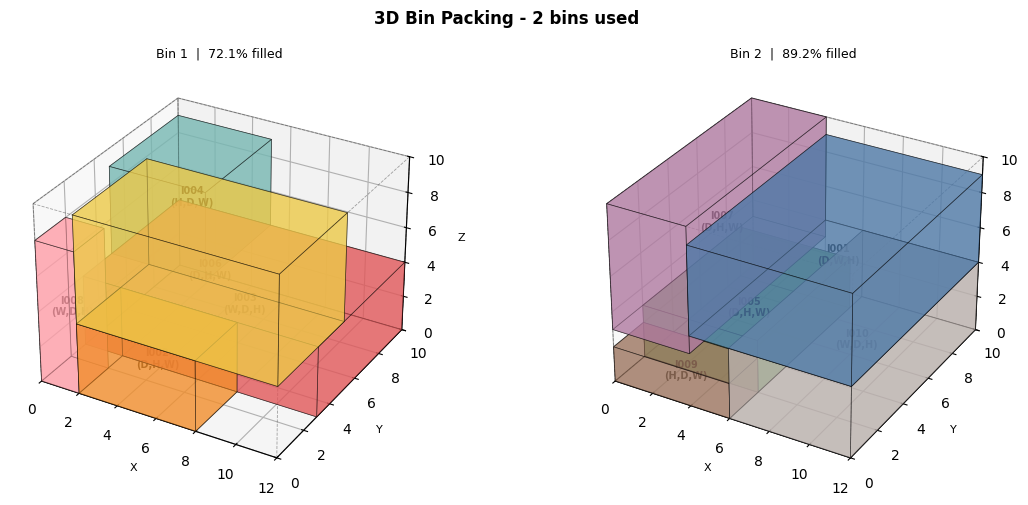

In [9]:
COLOR_PALETTE = [
    "#4E79A7", "#F28E2B", "#E15759", "#76B7B2",
    "#59A14F", "#EDC948", "#B07AA1", "#FF9DA7",
    "#9C755F", "#BAB0AC", "#8CD17D", "#D4A6C8",
    "#F1CE63", "#86BCB6", "#E45756"
]
ITEM_COLORS = {i: COLOR_PALETTE[idx % len(COLOR_PALETTE)] for idx, i in enumerate(I)}


def draw_box(ax, x0, y0, z0, w, d, h, color, alpha=0.55):
    """Draw a filled 3D box as a Poly3DCollection."""
    x1, y1, z1 = x0 + w, y0 + d, z0 + h
    faces = [
        [[x0, y0, z0], [x1, y0, z0], [x1, y1, z0], [x0, y1, z0]],  # bottom
        [[x0, y0, z1], [x1, y0, z1], [x1, y1, z1], [x0, y1, z1]],  # top
        [[x0, y0, z0], [x1, y0, z0], [x1, y0, z1], [x0, y0, z1]],  # front
        [[x0, y1, z0], [x1, y1, z0], [x1, y1, z1], [x0, y1, z1]],  # back
        [[x0, y0, z0], [x0, y1, z0], [x0, y1, z1], [x0, y0, z1]],  # left
        [[x1, y0, z0], [x1, y1, z0], [x1, y1, z1], [x1, y0, z1]],  # right
    ]
    ax.add_collection3d(Poly3DCollection(faces, alpha=alpha, facecolor=color, edgecolor='black', linewidth=0.5))


def draw_bin_outline(ax, W, D, H):
    """Draw the bin as a dashed wireframe."""
    for xv in [0, W]:
        for yv in [0, D]:
            ax.plot([xv, xv], [yv, yv], [0, H], 'k--', lw=0.6, alpha=0.35)
    for xv in [0, W]:
        for zv in [0, H]:
            ax.plot([xv, xv], [0, D], [zv, zv], 'k--', lw=0.6, alpha=0.35)
    for yv in [0, D]:
        for zv in [0, H]:
            ax.plot([0, W], [yv, yv], [zv, zv], 'k--', lw=0.6, alpha=0.35)


def plot_packing(packing, positions, orientations, title):
    """Draw each used bin with its items, one subplot per bin."""
    n_cols = min(3, len(packing))
    n_rows = int(np.ceil(len(packing) / n_cols))
    fig = plt.figure(figsize=(6 * n_cols, 5 * n_rows))

    for plot_idx, (j, item_list) in enumerate(packing.items()):
        ax = fig.add_subplot(n_rows, n_cols, plot_idx + 1, projection='3d')

        for i in item_list:
            x0, y0, z0 = positions[i]
            w_eff, d_eff, h_eff = eff_dims(i, orientations[i])
            draw_box(ax, x0, y0, z0, w_eff, d_eff, h_eff, color=ITEM_COLORS[i])
            ax.text(x0 + w_eff / 2, y0 + d_eff / 2, z0 + h_eff / 2, f"{i}\n{PERM_LABELS[orientations[i]]}",
                    ha='center', va='center', fontsize=7, fontweight='bold')

        draw_bin_outline(ax, BIN_WIDTH, BIN_DEPTH, BIN_HEIGHT)

        fill = 100.0 * sum(volumes[i] for i in item_list) / BIN_VOLUME
        ax.set_xlim(0, BIN_WIDTH)
        ax.set_ylim(0, BIN_DEPTH)
        ax.set_zlim(0, BIN_HEIGHT)
        ax.set_xlabel('X', fontsize=8)
        ax.set_ylabel('Y', fontsize=8)
        ax.set_zlabel('Z', fontsize=8)
        ax.set_title(f"Bin {j+1}  |  {fill:.1f}% filled", fontsize=9)

    fig.suptitle(title, fontsize=12, fontweight='bold')
    plt.tight_layout()
    plt.show()


plot_packing(packing, positions, orientations, f"3D Bin Packing - {len(packing)} bins used")

In [10]:
# Post-solution analysis with pandas
rows = []
for j, item_list in packing.items():
    vol_used = sum(volumes[i] for i in item_list)
    rows.append({
        "Bin": j + 1,
        "Items": ", ".join(item_list),
        "Volume Used": vol_used,
        "Free Volume": BIN_VOLUME - vol_used,
        "Fill %": round(100.0 * vol_used / BIN_VOLUME, 1),
    })

df_result = pd.DataFrame(rows)
display(HTML(df_result.to_html(index=False)))

print(f"Average bin fill rate : {df_result['Fill %'].mean():.1f}%")
print(f"Total wasted volume   : {df_result['Free Volume'].sum()} units³")

Bin,Items,Volume Used,Free Volume,Fill %
1,"I002, I003, I004, I006, I008",865,335,72.1
2,"I001, I005, I007, I009, I010",1070,130,89.2


Average bin fill rate : 80.7%
Total wasted volume   : 465 units³


### **1.4. Callback-Based Extension**

In Notebook 2 we used callbacks in the context of a small MINLP. Here we put the `NewPrimalSolution` callback to practical use: every time SHOT finds a new primal solution during the solve, our callback records it. Afterwards we use `pandas` and `matplotlib` to plot the full **primal/dual bound trajectory** — giving us a window into the solver's convergence.

We build the same model on a fresh solver with `build_binpacking_model()` and register the callback before calling `solveProblem()`.

In [11]:
# Create solver
solver2 = SHOTpy.Solver()
solver2.updateSetting("Dual.MIP.Solver", int(SHOTpy.MIPSolver.Highs))
solver2.updateSetting("Termination.TimeLimit", 60.0)

# Create problem
problem2, variables2 = build_binpacking_model(solver2)

# Set problem
assert solver2.setProblem(problem2)

# Register callback to track primal improvements
primal_log = []

def on_new_primal(ctx):
    primal_log.append({
        "iter": ctx.iterationNumber,
        "obj": ctx.objectiveValue,
        "dual": ctx.dualBound,
        "rel_gap_%": 100 * ctx.relativeGap,
        "solution": ctx.point,
    })

solver2.registerCallback(SHOTpy.CallbackLocation.NewPrimalSolution, on_new_primal)

# Solve
assert solver2.solveProblem()


 Performing bound tightening on original problem.
  - Bounds for 0 variables tightened in 0.00 s and 1 passes.
  - Objective bounds are: [0, 13440]

 Performing bound tightening on reformulated problem.
  - Bounds for 0 variables tightened in 0.00 s and 1 passes.
  - Objective bounds are: [0, 13440]
Running HiGHS 1.15.1 (git hash: 04024d7): Copyright (c) 2026 under MIT licence terms
Includes third-party software components, see THIRD_PARTY_NOTICES.md for full details
Rows:        1129 lower bounds    less than or equal to       -1e+20 are treated as -Infinity
Rows:        1129 lower bounds    less than or equal to       -1e+20 are treated as -Infinity

╶ Interior point search ──────────────────────────────────────────────────────────────────────────────────────────────╴

 Strategy selected:          cutting plane minimax

Running HiGHS 1.15.1 (git hash: 04024d7): Copyright (c) 2026 under MIT licence terms
Includes third-party software components, see THIRD_PARTY_NOTICES.md for full de

In [12]:
# Append the final solver state so the convergence plot extends to the end
primal_log.append({
    "iter": solver2.getSolutionStatistics().numberOfIterations,
    "obj": solver2.getPrimalBound(),
    "dual": solver2.getGlobalDualBound(),
    "rel_gap_%": 100 * solver2.getRelativeObjectiveGap(),
    "solution": solver2.getPrimalSolution().point,
})

print(f"Primal improvements recorded by callback: {len(primal_log) - 1} (plus the final state)\n")
print(f"  {'Iter':>6}  {'Objective':>10}  {'Dual Bound':>12}  {'Gap (%)':>8}")
print(f"  {'-'*6}  {'-'*10}  {'-'*12}  {'-'*8}")
for row in primal_log:
    print(f"  {row['iter']:>6}  {row['obj']:>10.1f}  {row['dual']:>12.1f}  {row['rel_gap_%']:>8.2f}")

Primal improvements recorded by callback: 12 (plus the final state)

    Iter   Objective    Dual Bound   Gap (%)
  ------  ----------  ------------  --------
       2      9392.0        1000.0     89.35
       4      7067.0        1000.0     85.85
       5      7036.2        1000.0     85.79
       5      2333.0        1000.0     57.14
       6      2319.0        2000.0     13.76
       7      2212.0        2000.0      9.58
       8      2186.0        2000.0      8.51
       8      2185.0        2000.0      8.47
       9      2172.0        2000.0      7.92
       9      2172.0        2000.0      7.92
      10      2159.0        2000.0      7.36
      11      2155.0        2042.3      5.23
      11      2155.0        2042.3      5.23


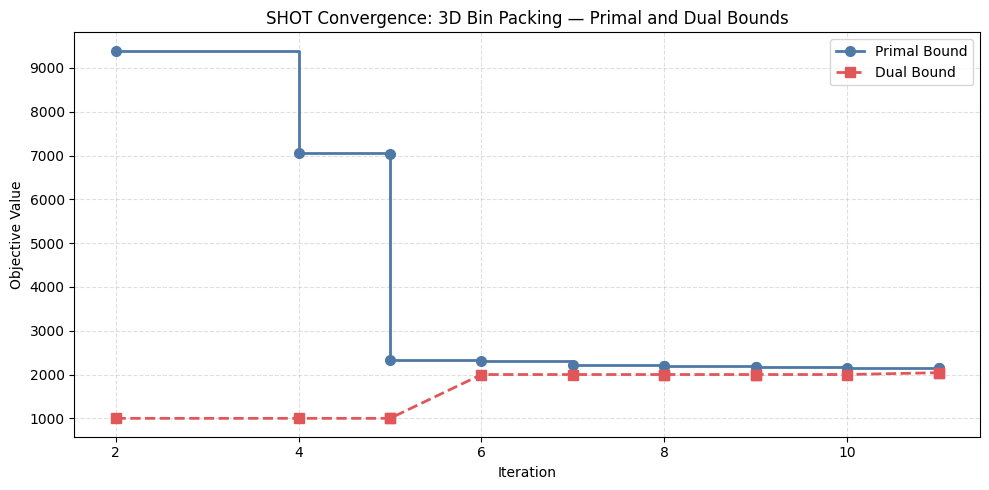

In [13]:
# Convergence plot
df_conv = pd.DataFrame(primal_log).sort_values("iter", kind="stable")
dual_finite = df_conv[np.isfinite(df_conv["dual"])]

fig, ax = plt.subplots(figsize=(10, 5))

ax.step(df_conv["iter"], df_conv["obj"], where="post", linewidth=2, label="Primal Bound",
        marker="o", markersize=7, color="#4E79A7")
ax.plot(dual_finite["iter"], dual_finite["dual"], linewidth=2, linestyle="--", label="Dual Bound",
        marker="s", markersize=7, color="#E15759")

ax.set_xlabel("Iteration")
ax.set_ylabel("Objective Value")
ax.set_title("SHOT Convergence: 3D Bin Packing — Primal and Dual Bounds")
ax.legend()
ax.grid(True, linestyle="--", alpha=0.4)
ax.yaxis.set_major_locator(plt.MaxNLocator(integer=True))
plt.tight_layout()
plt.show()

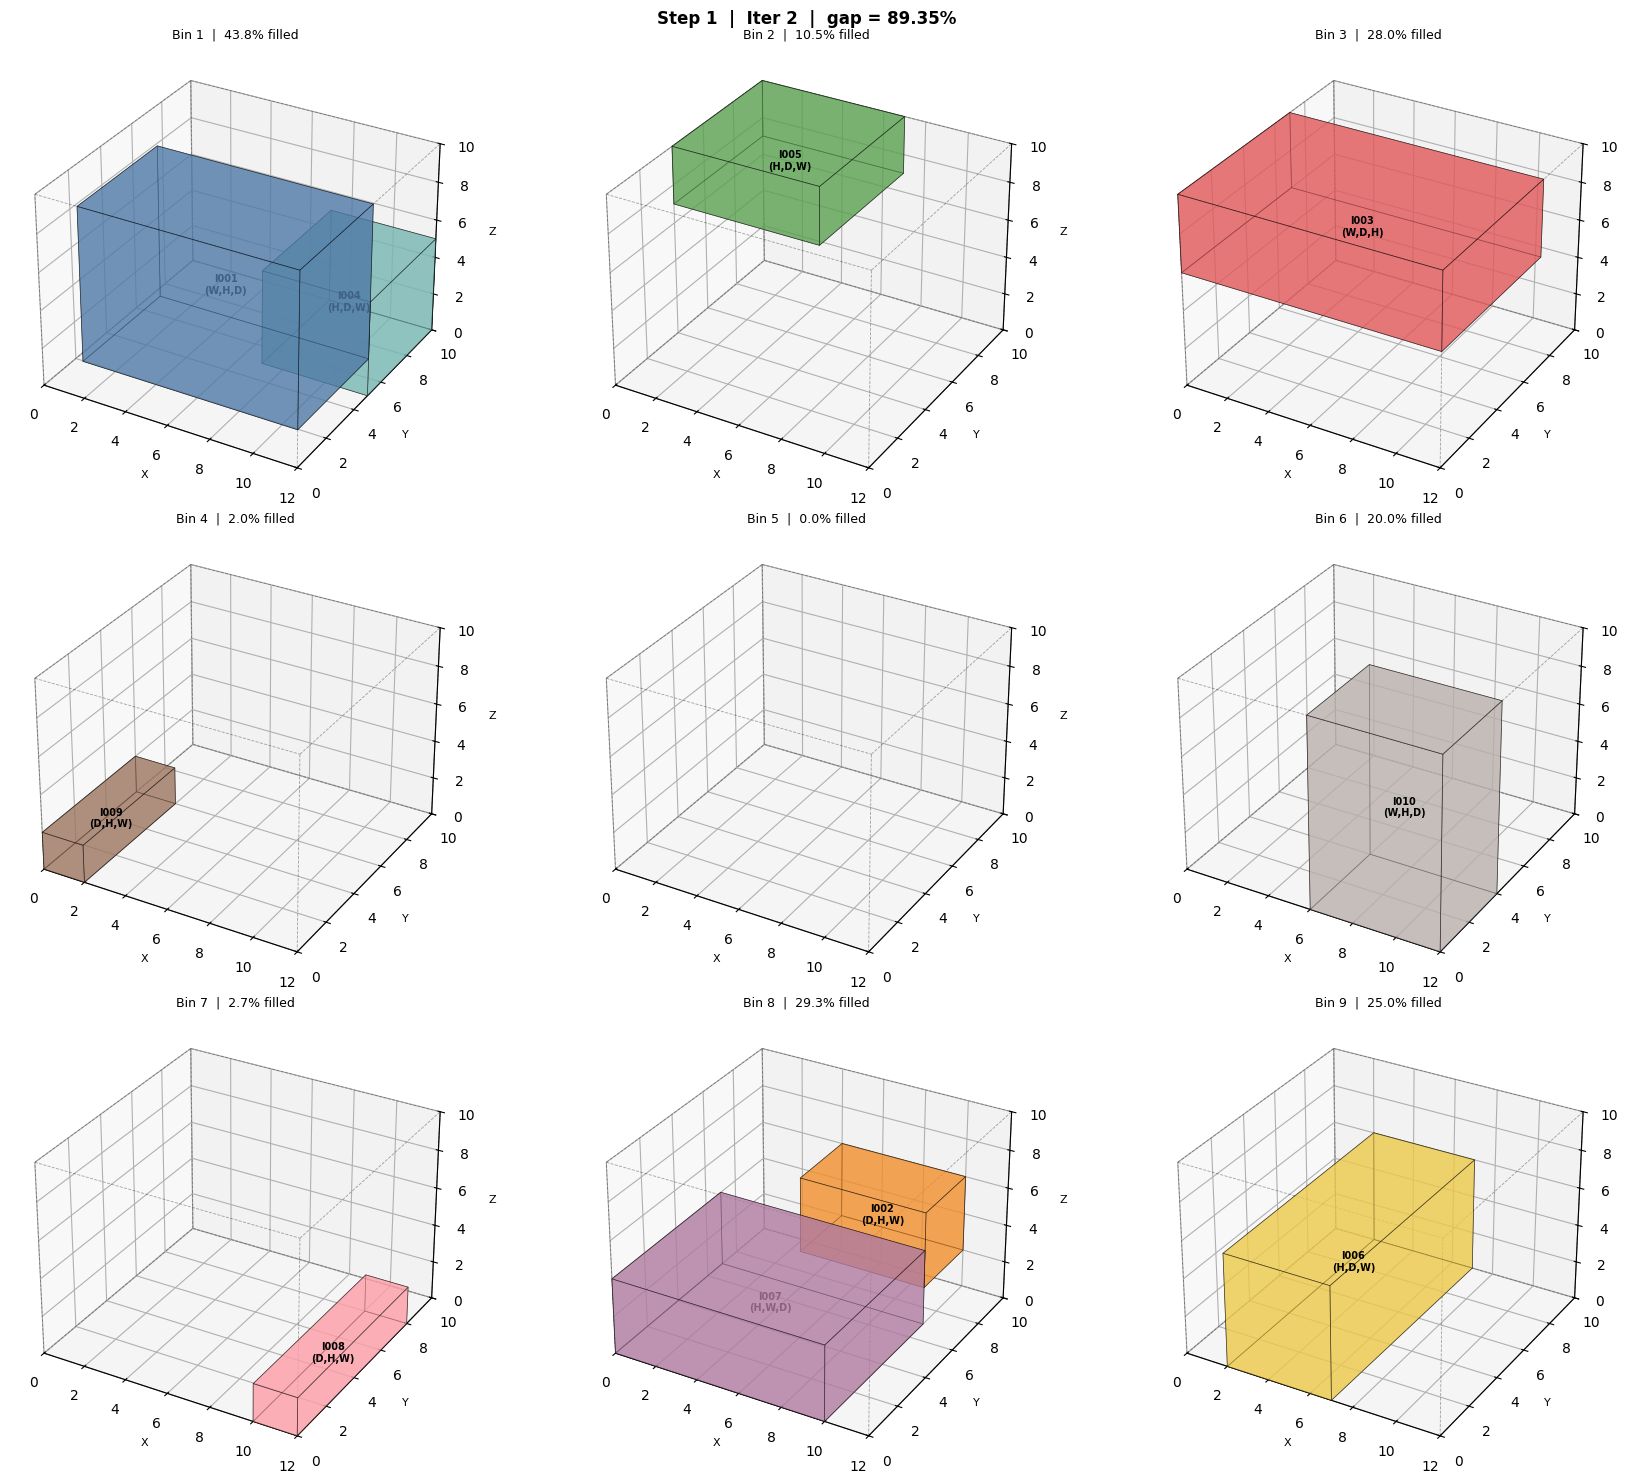

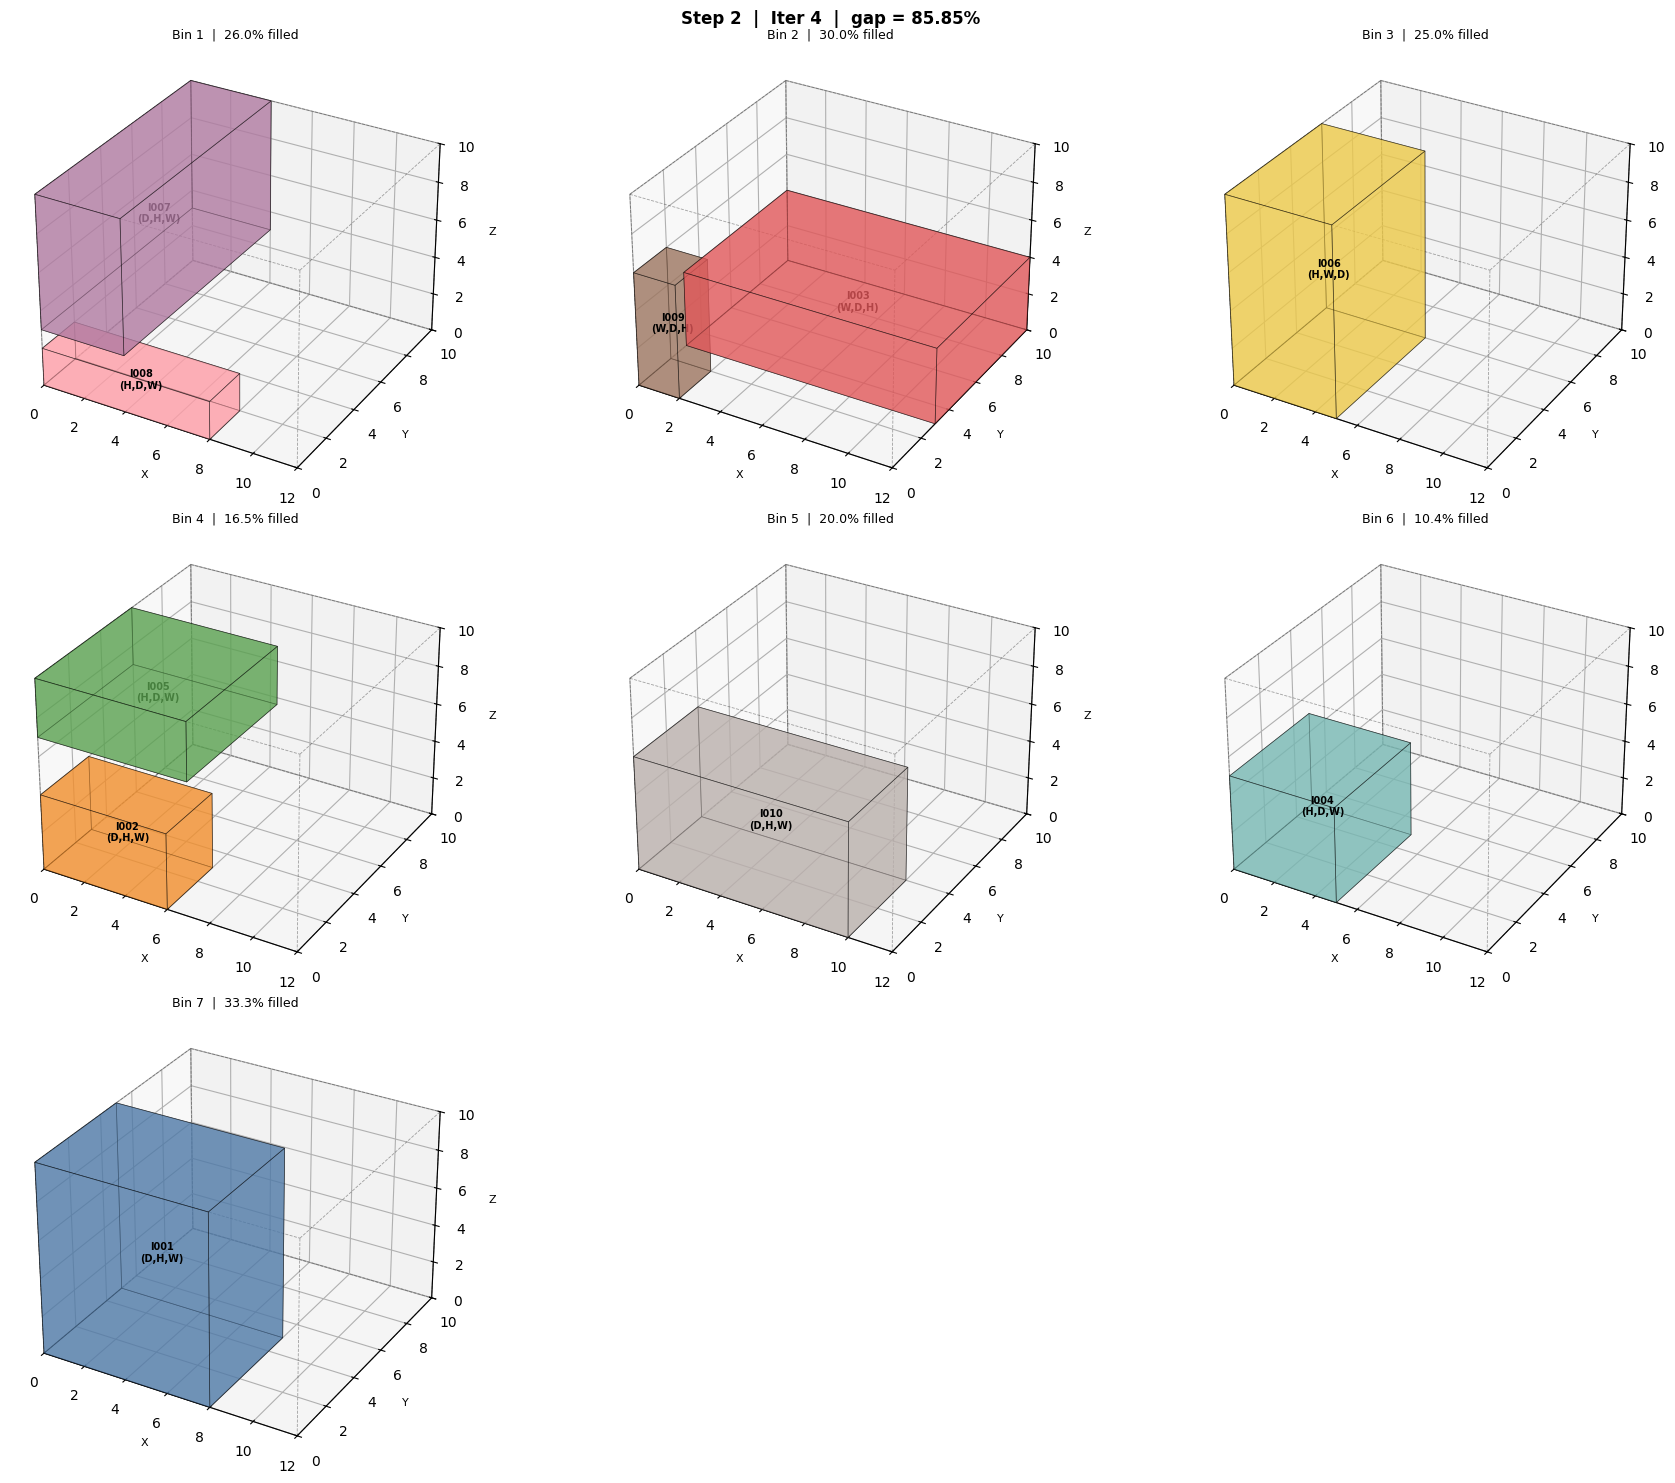

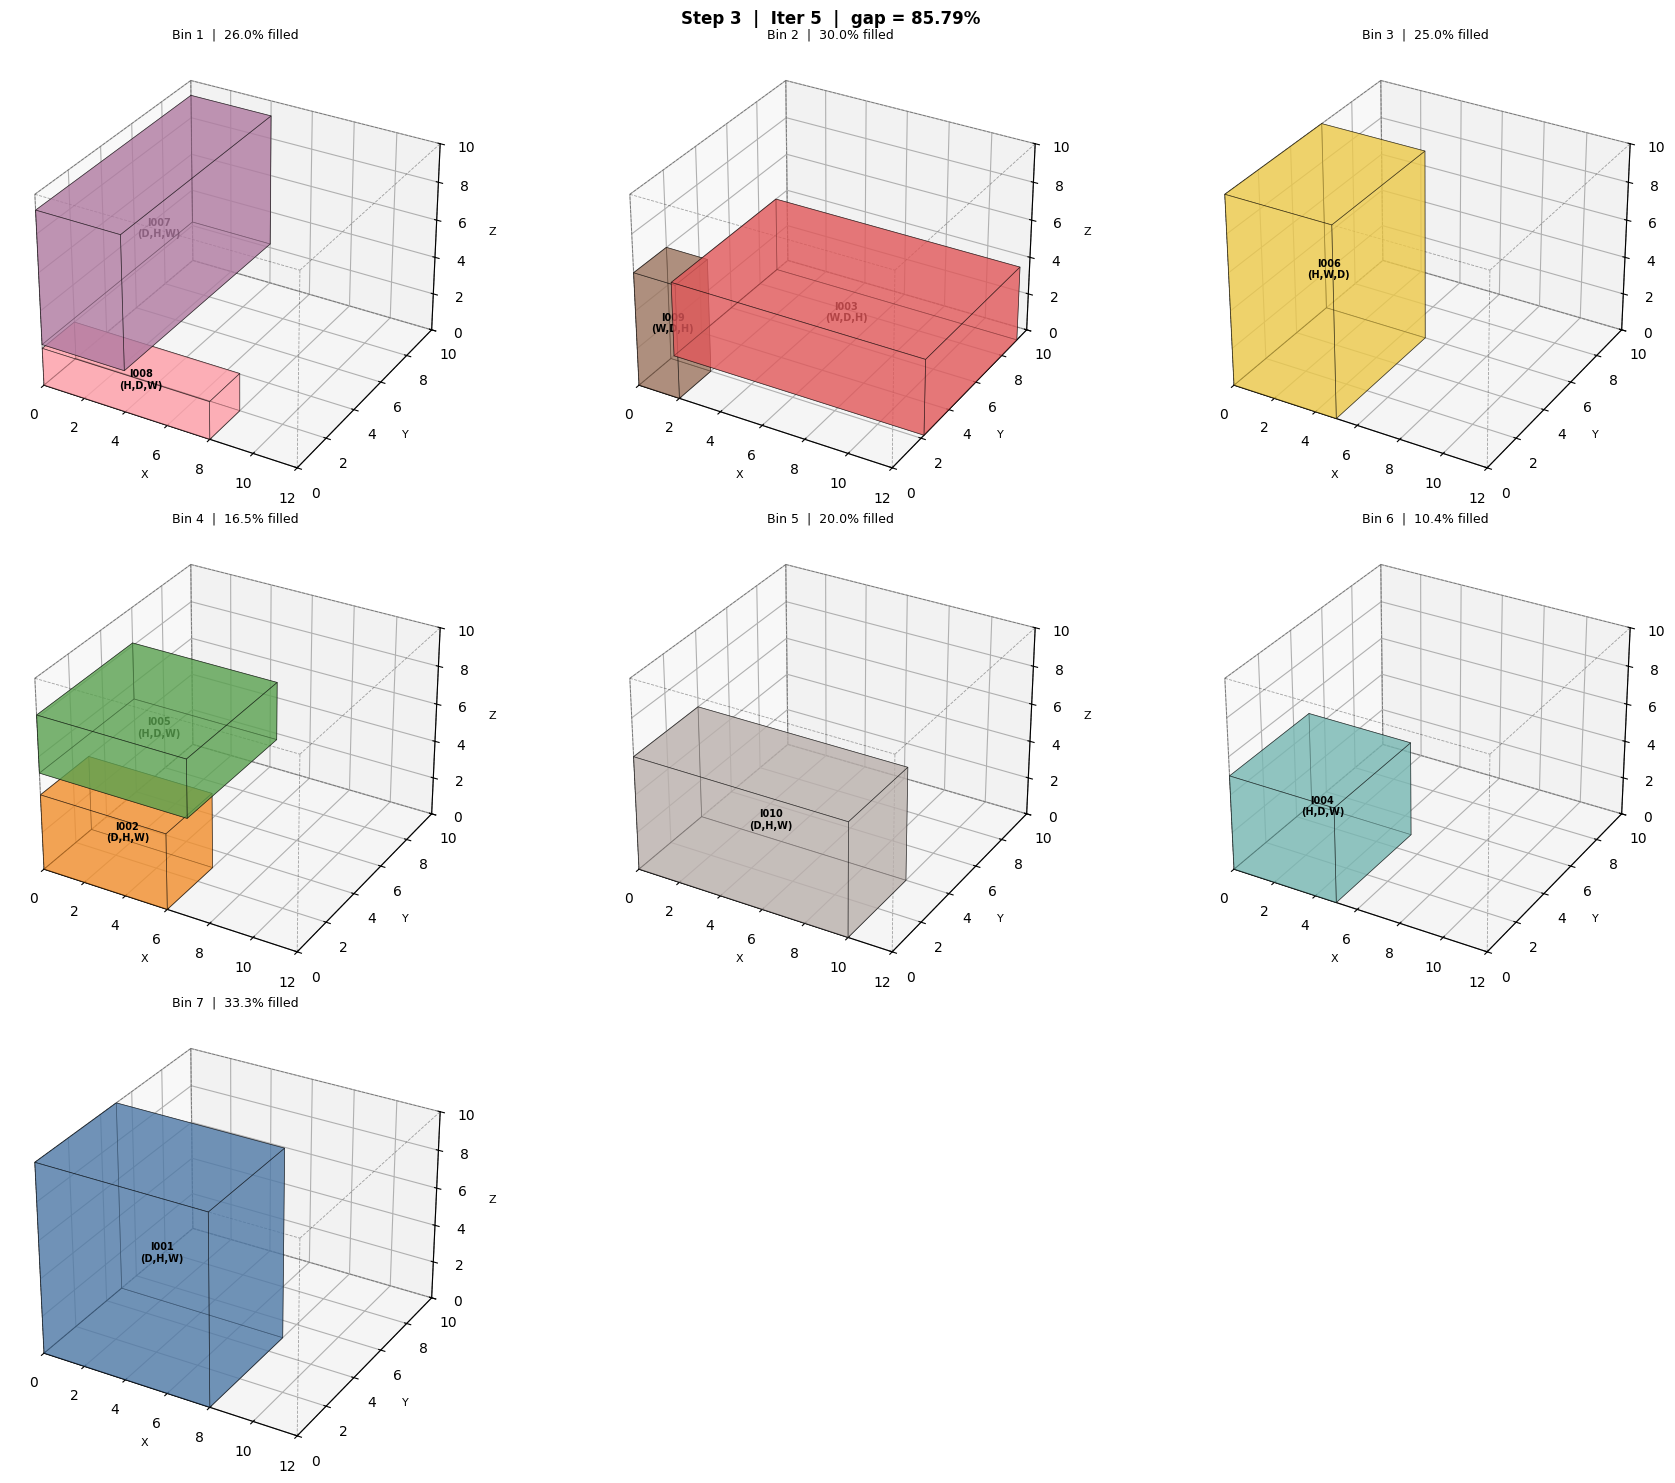

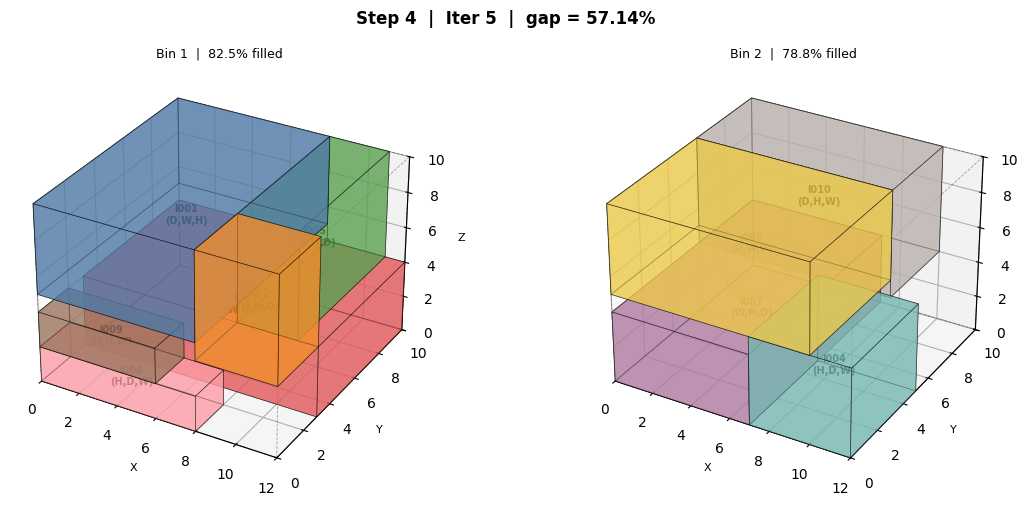

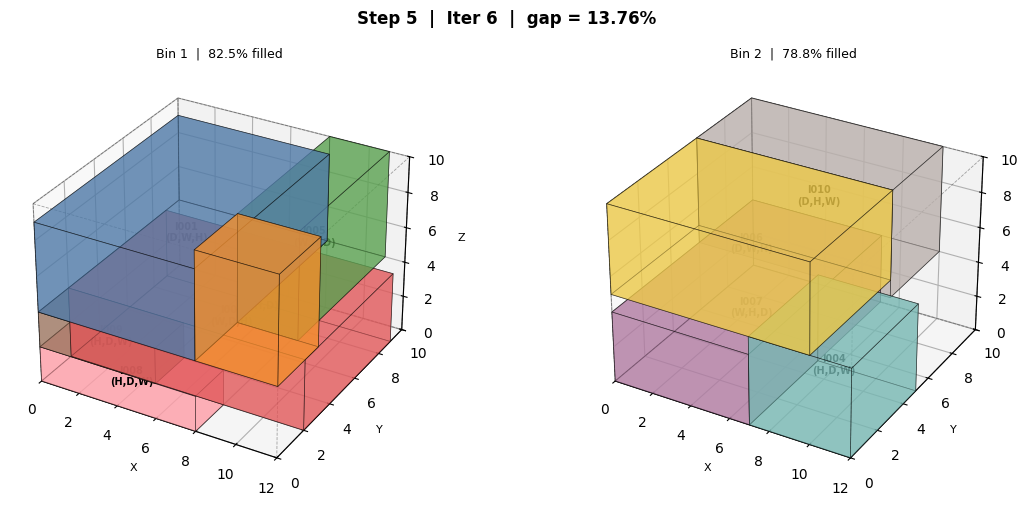

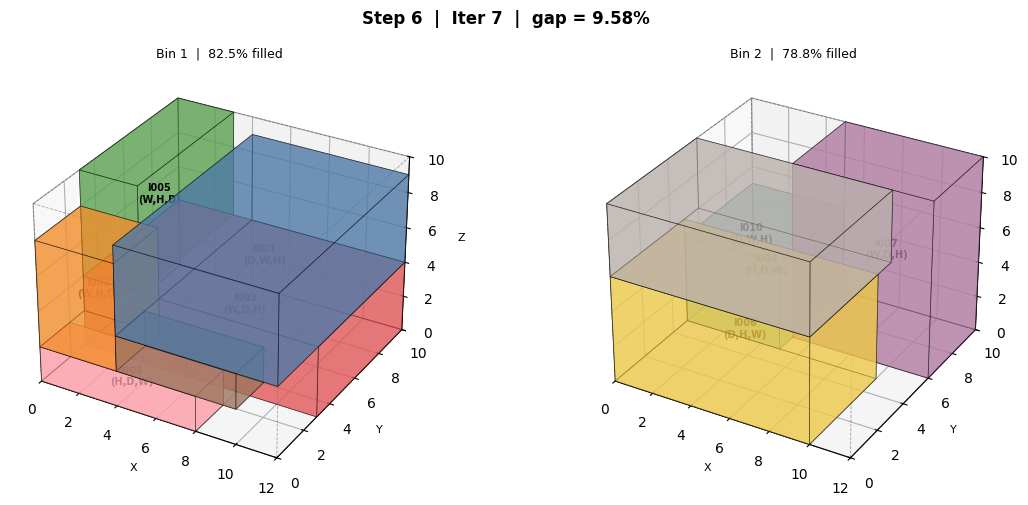

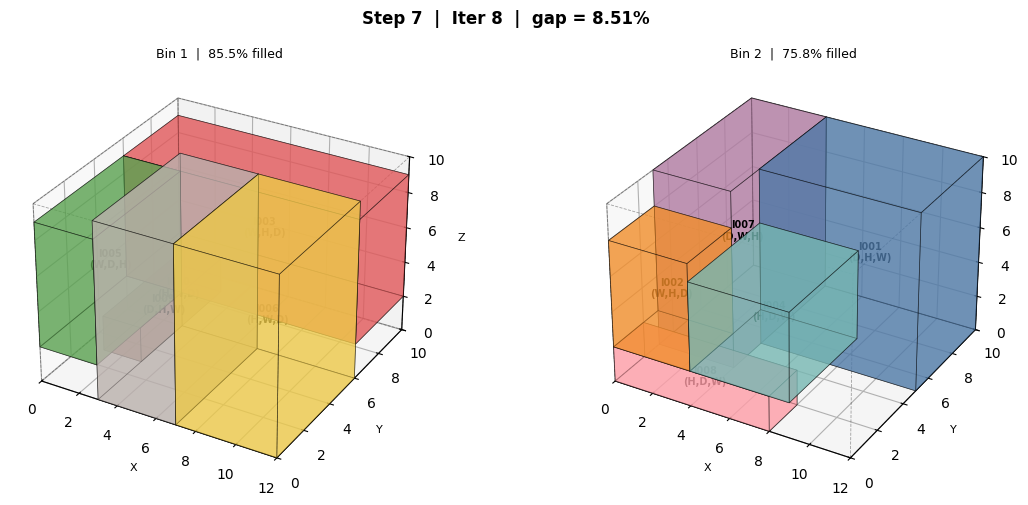

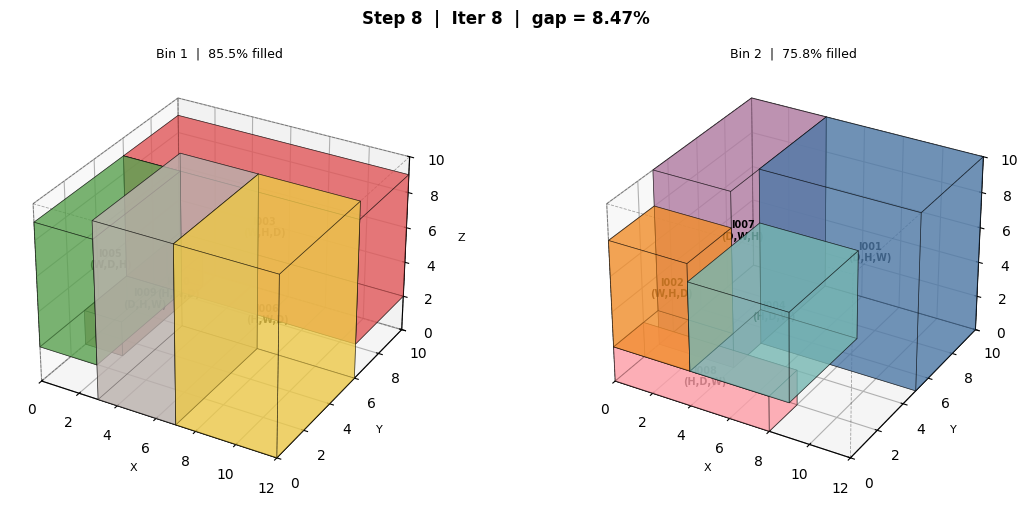

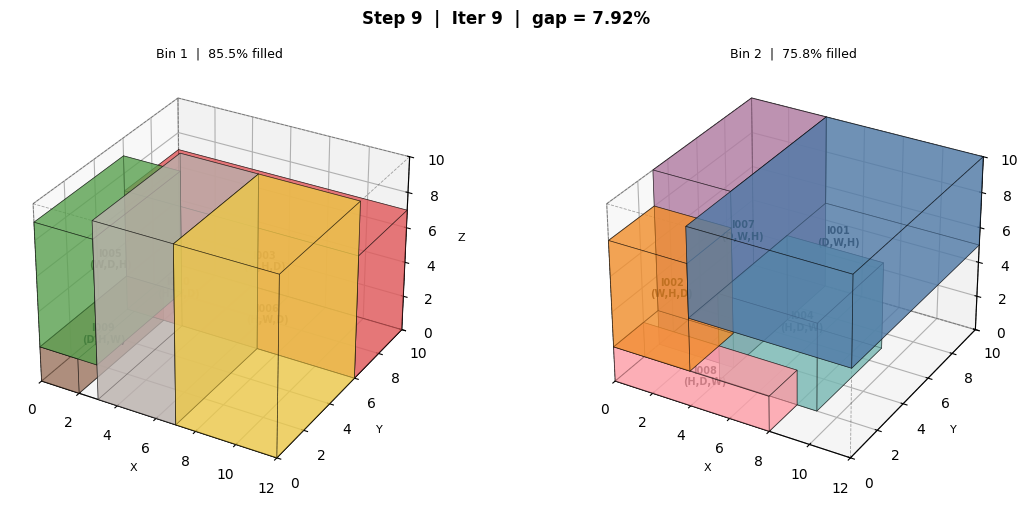

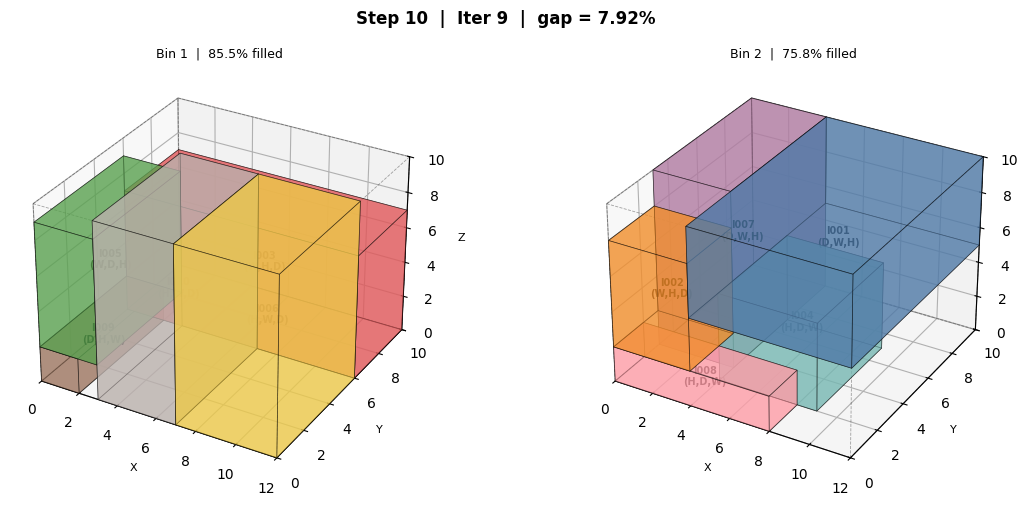

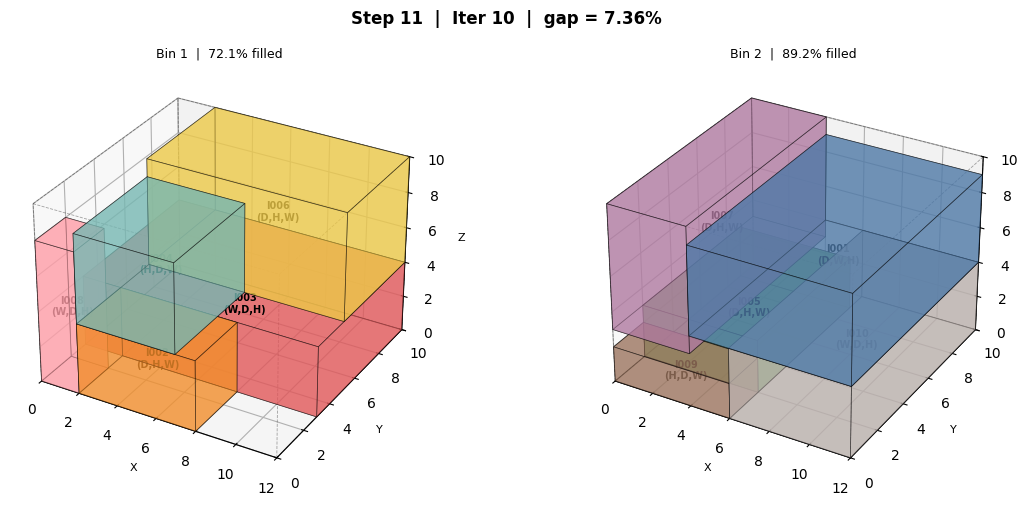

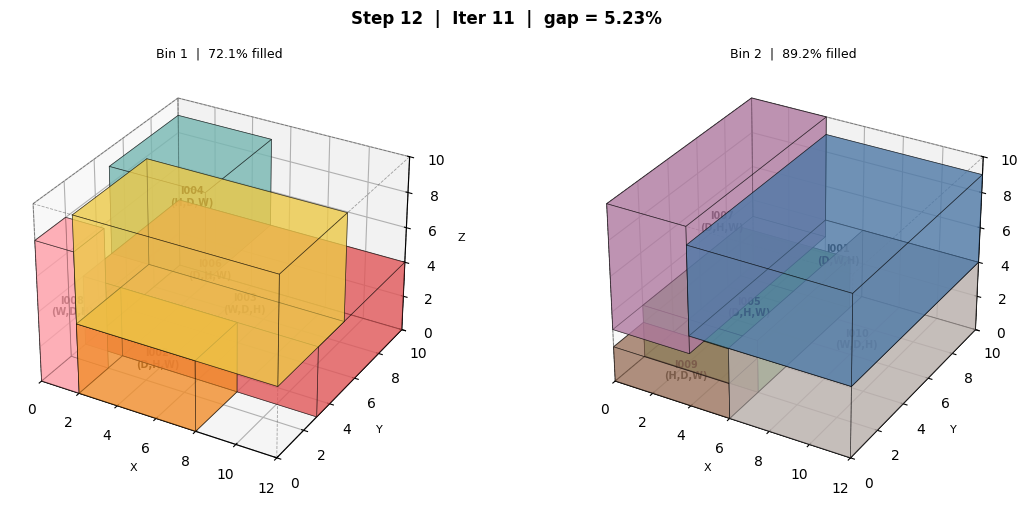

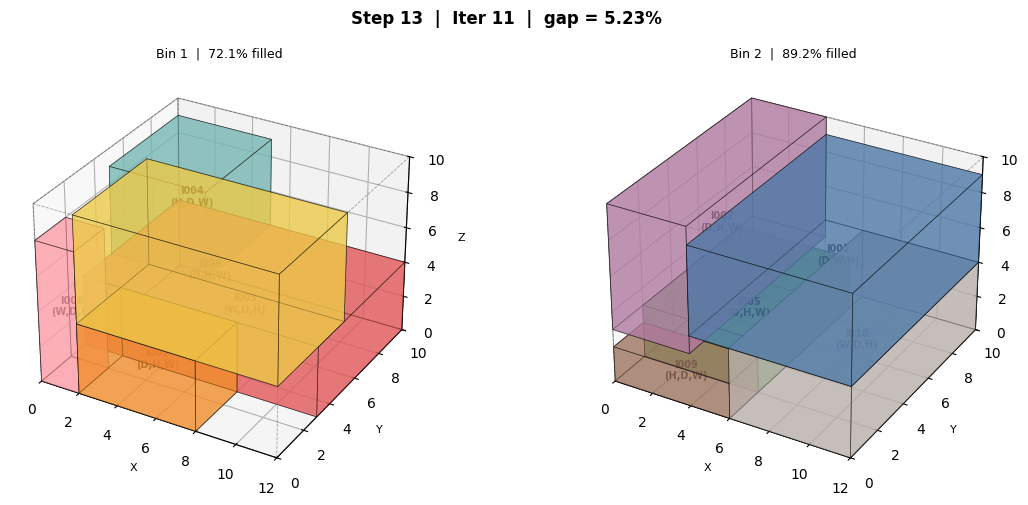

In [14]:
# Visualize the 3D packing at each primal improvement step
for step, row in enumerate(primal_log):
    step_packing, step_positions, step_orientations = decode_packing(row["solution"], variables2)
    plot_packing(step_packing, step_positions, step_orientations,
                 f"Step {step+1}  |  Iter {row['iter']}  |  gap = {row['rel_gap_%']:.2f}%")

## **2. Key Takeaways**

### 1. **Utilize Your Favorite Python Libraries**
You can seamlessly combine SHOTpy with standard Python libraries: `pandas` handles data loading and postprocessing, `numpy` provides quick statistics, and `matplotlib` turns abstract solution vectors into intuitive visual summaries (to name a few). The solver becomes just one component in a larger data workflow.

### 2. **Callbacks Bridge the Solver and Your Application**
Callbacks are not just a research tool — they let you instrument any production workflow. In this notebook we used `NewPrimalSolution` to capture the full convergence history and replay each intermediate packing visually. The same pattern works for writing solutions to a database, updating a dashboard, triggering alerts, or feeding results into a downstream pipeline — all without waiting for the full solve to finish. This makes SHOT a first-class citizen in any real-time or iterative decision-support workflow, not just a standalone black box.

### 3. **SHOTpy Enables You to Build More Than Optimization Models**
SHOTpy bridges the gap between optimization research and real-world applications. The same Python interface can be used to prototype new ideas, analyze solver performance, build visualizations, and integrate optimization into larger software systems. This flexibility makes SHOTpy a powerful tool for both researchers and practitioners.

### **Next Steps**
In **Notebook 4**, you'll learn more about advanced modeling, *e.g.*, how to analyze the functions of a model in Python: evaluating values, gradients and Hessians, bounding them with interval arithmetic, checking convexity numerically, and constructing αBB underestimators.